In [1]:
import pandas as pd
import sklearn as sk
import numpy as np
import matplotlib.pyplot as plt
from glob import glob

<h1>1.0 Import Ride and Zone Lookup Data</h1>

<h2>1.1 Import Ride Data</h2>

In [2]:
rides_dtypes = dict(
    VendorID=int,
    tpep_pickup_datetime=str,
    tpep_dropoff_datetime=str,
    passenger_count=float,
    trip_distance=float,
    RatecodeID=float,
    store_and_fwd_flag=str,
    PULocationID=int,
    DOLocationID=int,
    payment_type=int,
    fare_amount=float,
    extra=float,
    mta_tax=float,
    tip_amount=float,
    tolls_amount=float,
    improvement_surcharge=float,
    total_amount=float,
    congestion_surcharge=float,
    Airport_fee=float,
)

In [3]:
ENTIRE_DATASET = False

if ENTIRE_DATASET:
    rides = pd.concat([
        pd.read_csv(x, dtype=rides_dtypes)
        for x in glob("../dataset/rides_train_*.csv")
        if "sample" not in x
    ])
else:
    rides = pd.read_csv(
        "../dataset/rides_train_sample.csv",
        dtype=rides_dtypes,
    )

<h2>1.2 Import Zone Lookup Data</h2>

In [5]:
# Find Manhattan zone IDs for filtering up next
zones = pd.read_csv('../dataset/taxi_zone_lookup.csv')
manhat_zones = zones[zones['Borough'] == 'Manhattan']['LocationID']

<h2>1.3 Check Data Imports</h2>

In [6]:
# rides.shape
# rides.info()
#rides.describe()
#rides.head()

zones.info()
#manhat_zones.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   LocationID    265 non-null    int64 
 1   Borough       264 non-null    object
 2   Zone          264 non-null    object
 3   service_zone  263 non-null    object
dtypes: int64(1), object(3)
memory usage: 8.4+ KB


<h1>2.0 Filtering and Exploring the Data</h1>

<h2>2.1 Filter for Manhattan Pickup Zones</h2>

In [7]:
manhat_rides = rides[rides['PULocationID'].isin(manhat_zones)].copy()

<h2>2.2 Check the filtered dataframe</h2>

In [8]:
# manhat_rides.shape
# manhat_rides.info()
manhat_rides.describe()

,Unnamed: 0,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
count,1.766579e+06,1.766579e+06,1.596157e+06,1.766579e+06,1.596157e+06,1.766579e+06,1.766579e+06,1.766579e+06,1.766579e+06,1.766579e+06,1.766579e+06,1.766579e+06,1.766579e+06,1.766579e+06,1.766579e+06,1.596157e+06,1.596157e+06
mean,1.677737e+06,1.764988e+00,1.329723e+00,3.726164e+00,1.468517e+00,1.681171e+02,1.651059e+02,1.100885e+00,1.593618e+01,1.239918e+00,4.831154e-01,2.827637e+00,2.354296e-01,9.711522e-01,2.355578e+01,2.366292e+00,1.118311e-04
std,1.110320e+06,4.245200e-01,8.160460e-01,3.525203e+02,6.476389e+00,6.531588e+01,6.865372e+01,6.327816e-01,2.556312e+02,1.506922e+00,1.212323e-01,3.058653e+00,1.592578e+00,2.324736e-01,2.558104e+02,6.992403e-01,1.567091e-02
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,0.000000e+00,-7.485000e+02,-7.500000e+00,-5.000000e-01,-9.901000e+01,-4.600000e+01,-1.000000e+00,-7.633800e+02,-2.500000e+00,-1.750000e+00
25%,6.530015e+05,2.000000e+00,1.000000e+00,9.800000e-01,1.000000e+00,1.370000e+02,1.140000e+02,1.000000e+00,8.600000e+00,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.540000e+01,2.500000e+00,0.000000e+00
50%,1.393026e+06,2.000000e+00,1.000000e+00,1.600000e+00,1.000000e+00,1.630000e+02,1.620000e+02,1.000000e+00,1.280000e+01,1.000000e+00,5.000000e-01,2.560000e+00,0.000000e+00,1.000000e+00,1.990000e+01,2.500000e+00,0.000000e+00
75%,2.687831e+06,2.000000e+00,1.000000e+00,2.680000e+00,1.000000e+00,2.340000e+02,2.340000e+02,1.000000e+00,1.910000e+01,2.500000e+00,5.000000e-01,3.980000e+00,0.000000e+00,1.000000e+00,2.690000e+01,2.500000e+00,0.000000e+00
max,3.833770e+06,7.000000e+00,9.000000e+00,2.232228e+05,9.900000e+01,2.630000e+02,2.650000e+02,4.000000e+00,3.355444e+05,1.444000e+01,1.050000e+01,2.156600e+02,9.999000e+01,1.000000e+00,3.355509e+05,2.500000e+00,1.750000e+00


<h2>2.3 Check for missing data in general</h2>

In [9]:
print(manhat_rides.isna().mean() * 100)

Unnamed: 0               0.000000
VendorID                 0.000000
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
passenger_count          9.647007
trip_distance            0.000000
RatecodeID               9.647007
store_and_fwd_flag       9.647007
PULocationID             0.000000
DOLocationID             0.000000
payment_type             0.000000
fare_amount              0.000000
extra                    0.000000
mta_tax                  0.000000
tip_amount               0.000000
tolls_amount             0.000000
improvement_surcharge    0.000000
total_amount             0.000000
congestion_surcharge     9.647007
Airport_fee              9.647007
dtype: float64


<h2>2.4 Check for missing data by vendor</h2>

In [10]:
missing_by_vendor = (
    manhat_rides
    .isna()
    .groupby(manhat_rides['VendorID'])
    .mean() * 100
).round(5)

missing_by_vendor = missing_by_vendor.loc[:, (missing_by_vendor > 0).any()]

print(missing_by_vendor)

          passenger_count  RatecodeID  store_and_fwd_flag  \
VendorID                                                    
1                 9.07486     9.07486             9.07486   
2                 9.82125     9.82125             9.82125   
6               100.00000   100.00000           100.00000   
7                 0.00000     0.00000             0.00000   

          congestion_surcharge  Airport_fee  
VendorID                                     
1                      9.07486      9.07486  
2                      9.82125      9.82125  
6                    100.00000    100.00000  
7                      0.00000      0.00000  


<h2>2.5 Updating data types</h2>

In [11]:
# Convert to datetime
manhat_rides['tpep_pickup_datetime'] = pd.to_datetime(
    manhat_rides['tpep_pickup_datetime'],
    errors='coerce'
)

manhat_rides['tpep_dropoff_datetime'] = pd.to_datetime(
    manhat_rides['tpep_dropoff_datetime'],
    errors='coerce'
)

# Convert Y/N to boolean
manhat_rides['store_and_fwd_flag'] = (
    manhat_rides['store_and_fwd_flag']
    .map({'Y': True, 'N': False})
    .astype('boolean') # just for reference clarity
)

<h2>2.6 Check data types</h2>

In [12]:
manhat_rides.dtypes

Unnamed: 0                        int64
VendorID                          int64
tpep_pickup_datetime     datetime64[ns]
tpep_dropoff_datetime    datetime64[ns]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag              boolean
PULocationID                      int64
DOLocationID                      int64
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
dtype: object

<h2>2.7 Add a duration and avg speed column for validation</h2>

In [13]:
# Duration in hours
manhat_rides['duration_hours'] = (
    (manhat_rides['tpep_dropoff_datetime'] - manhat_rides['tpep_pickup_datetime'])
    .dt.total_seconds() / 3600
)

# Average speed (mph)
manhat_rides['avg_speed_mph'] = (
    manhat_rides['trip_distance'] /
    manhat_rides['duration_hours'].replace(0, np.nan)
)

<h2>2.8 Feature plotting for understanding</h2>

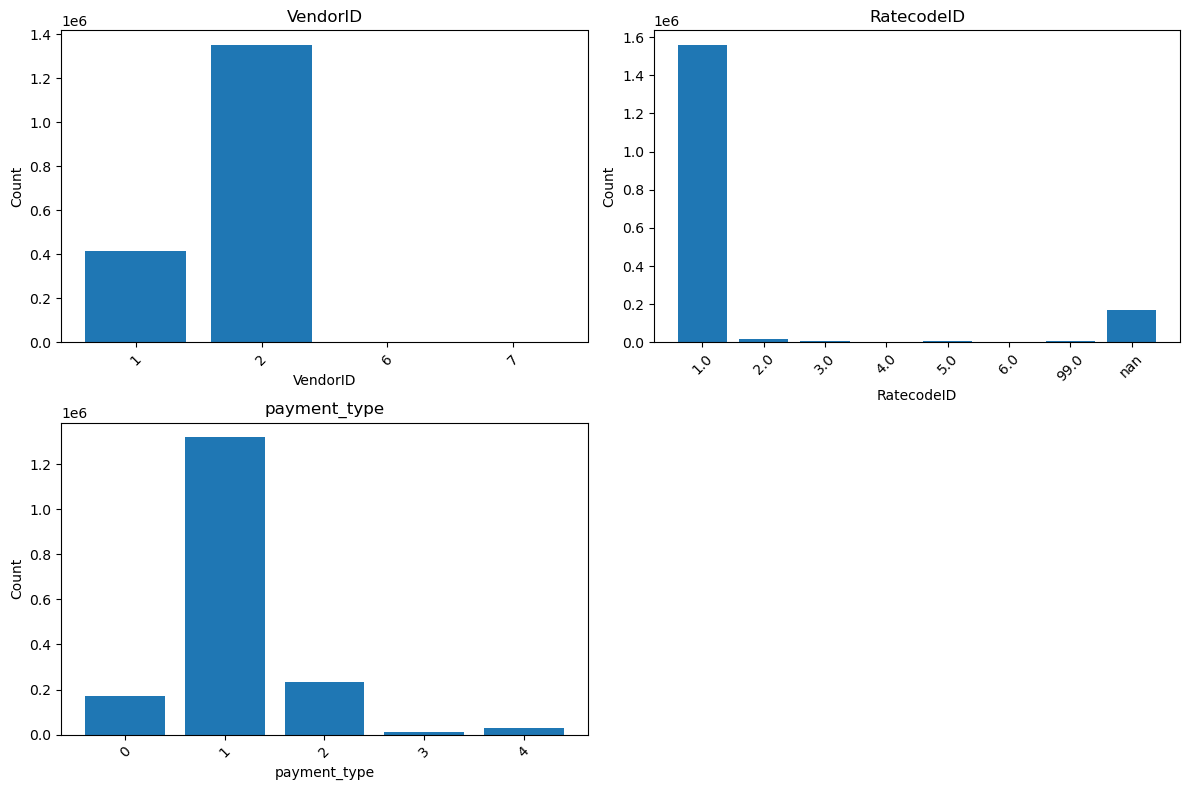

In [14]:
# label the cateogricals - ignore "store_and_fwd_flag" because it is not at all useful.
raw_categorical = [
    "VendorID",
    "RatecodeID",
    "payment_type",
]

# Construct some bar charts of the categorical variables so we can see the distribution and observe outliers.

n = len(raw_categorical)
cols = 2
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))
axes = axes.flatten()

for i, col in enumerate(raw_categorical):
    counts = manhat_rides[col].value_counts(dropna=False).sort_index()
    
    axes[i].bar(counts.index.astype(str), counts.values)
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=45)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

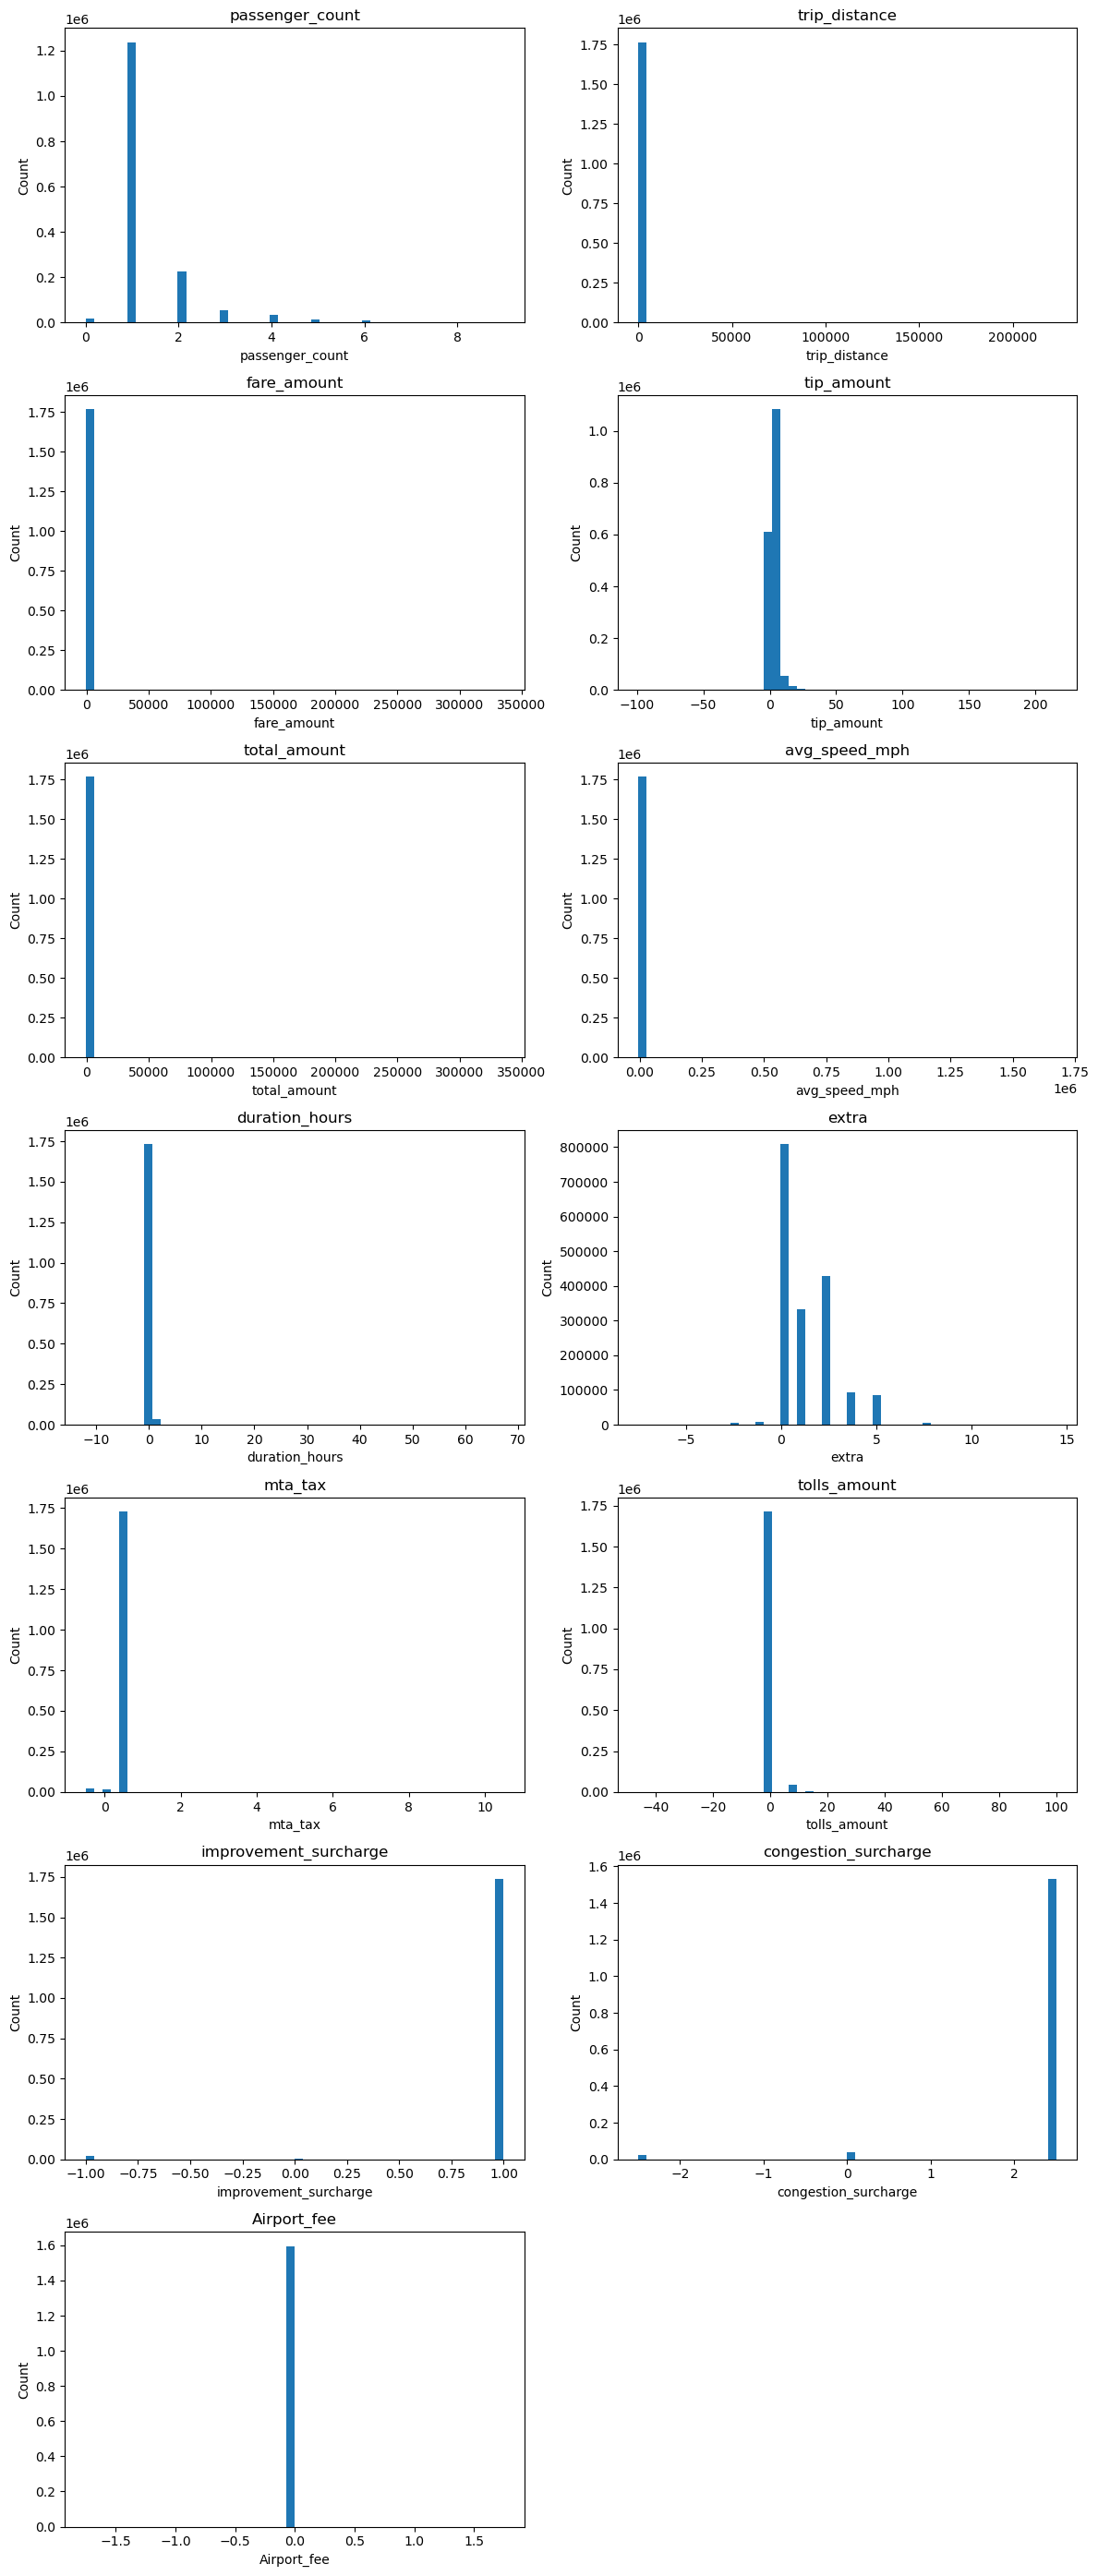

In [15]:
raw_numeric = [
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "avg_speed_mph",
    "duration_hours",
    "extra",
    "mta_tax",
    "tolls_amount",
    "improvement_surcharge",
    "congestion_surcharge",
    "Airport_fee"
]

# Construct some binned histograms of the numerical variables so we can see the distribution and observe outliers.


n = len(raw_numeric)
cols = 2
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))
axes = axes.flatten()

for i, col in enumerate(raw_numeric):
    axes[i].hist(manhat_rides[col].dropna(), bins=50)
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

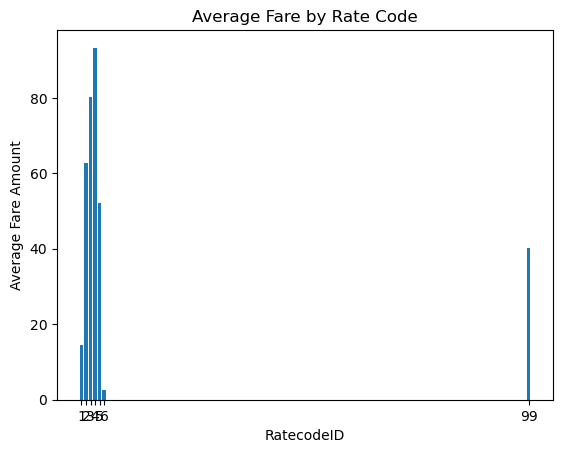

In [16]:
avg_fare_by_rate = manhat_rides.groupby("RatecodeID")["fare_amount"].mean().reset_index()

plt.figure()
plt.bar(avg_fare_by_rate["RatecodeID"], avg_fare_by_rate["fare_amount"])

plt.xlabel("RatecodeID")
plt.ylabel("Average Fare Amount")
plt.title("Average Fare by Rate Code")

plt.xticks(avg_fare_by_rate["RatecodeID"])
plt.show()

<h2>2.9 Preliminary feature evaluation</h2>

| Feature                  | Type        | Missing Data | Probably Important | Sig. Outliers | Notes |
|--------------------------|------------|------|------|------|------|
| VendorID                | Categorical | No | No | N/A |  |
| tpep_pickup_datetime    | Datetime    | No | Yes | N/A | Needs conversion |
| tpep_dropoff_datetime   | Datetime    | No | Yes | N/A | Same, leakage risk! |
| passenger_count         | Discrete    | Yes | No | No | Leakage risk|
| trip_distance           | Continuous  | No | No | Yes | Leakage risk|
| RatecodeID              | Categorical | Yes | Yes | No |  | Large differences in avg fare
| store_and_fwd_flag      | Boolean     | Yes | No | No | Apparently useless |
| PULocationID            | Categorical | No | Yes | No |  |
| DOLocationID            | Categorical | No | Yes | No |  |
| payment_type            | Categorical | No | No | No |  |
| fare_amount             | Continuous  | No | No | Yes | Part of revenue |
| extra                   | Continuous  | No | No | No | Part of revenue |
| mta_tax                 | Continuous  | No | No | Yes* | Part of revenue; *do not make a big difference as numbers are small |
| tip_amount              | Continuous  | No | No | No | Part of revenue |
| tolls_amount            | Continuous  | No | No | No | Part of revenue |
| improvement_surcharge   | Continuous  | No | No | No | Part of revenue |
| total_amount            | Continuous  | No | Yes | Yes |  Target variable (revenue) |
| congestion_surcharge    | Continuous  | Yes | No | No | Part of revenue |
| airport_fee             | Continuous  | Yes | No | No | Part of revenue |
| duration_hours          | Continuous  | No | Yes | Yes | Massive outliers |
| avg_speed_mph           | Continuous  | No | Yes | Yes | Massive outliers |

<h1>3.0 Finding Data Discrepancies and Cleaning</h1>

In [17]:
# Based on the above, we want to investigate trip_distance, fare_amount, mta_tax, total_amount, duration_hours, avg_speed_mph

# All negative values must be removed.

# Need to determine cut-off points for the others, to prevent enormous outliers from biasing the models.
# Below, we try some potential cut-offs and oberve ho

print("Counts of extreme / invalid values:\n")

checks = {
    "total_amount > 1000": ("total_amount", manhat_rides["total_amount"] > 1000),
    "total_amount < 0.0": ("total_amount", manhat_rides["total_amount"] <= 0.0),
    "avg_speed_mph > 150": ("avg_speed_mph", manhat_rides["avg_speed_mph"] > 150),
    "avg_speed_mph < 1": ("avg_speed_mph", manhat_rides["avg_speed_mph"] < 1),
    "duration_hours > 12": ("duration_hours", manhat_rides["duration_hours"] > 12),
    "duration_hours < 0.01": ("duration_hours", manhat_rides["duration_hours"] < 0.01),
}

for name, (col, condition) in checks.items():
    full_col = manhat_rides[col]
    flagged = full_col[condition]
    count = condition.sum()

    if count > 0:
        # quantile position in the FULL distribution
        q_low = (full_col <= flagged.min()).mean()
        q_high = (full_col <= flagged.max()).mean()

        print(
            f"{name}: {count} | "
            f"value range: {flagged.min():.4f} to {flagged.max():.4f} | "
            f"full-sample quantile range: {q_low:.4f} to {q_high:.4f}"
        )
    else:
        print(f"{name}: {count}")

Counts of extreme / invalid values:

total_amount > 1000: 3 | value range: 3037.1000 to 335550.9400 | full-sample quantile range: 1.0000 to 1.0000
total_amount < 0.0: 23274 | value range: -763.3800 to 0.0000 | full-sample quantile range: 0.0000 to 0.0132
avg_speed_mph > 150: 298 | value range: 153.0000 to 1674170.9250 | full-sample quantile range: 0.9996 to 0.9998
avg_speed_mph < 1: 30895 | value range: -5202.0000 to 0.9984 | full-sample quantile range: 0.0000 to 0.0175
duration_hours > 12: 802 | value range: 12.1228 to 67.2794 | full-sample quantile range: 0.9995 to 1.0000
duration_hours < 0.01: 12468 | value range: -11.9447 to 0.0097 | full-sample quantile range: 0.0000 to 0.0071


<h2>3.1 Finding unphysical data</h2>

In [18]:
def get_constraint_violations(df):

    violations = {}
    # These are the cut-offs we apply to the data. They are decided and refined using statistical assessment in 3.0 and checked using 3.2
    # The conditions describe what data will be flagged
    possible_checks = {
        'passenger_count': lambda x: x < 0,
        'trip_distance': lambda x: (x <= 0) | (x > 400), # to ensure the taxi actually moved
        'fare_amount': lambda x: (x < 0) | (x > 3000),
        'extra': lambda x: x < 0,
        'mta_tax': lambda x: x < 0,
        'tip_amount': lambda x: x < 0,
        'tolls_amount': lambda x: x < 0,
        'improvement_surcharge': lambda x: x < 0,
        'total_amount': lambda x: x < 0,
        'congestion_surcharge': lambda x: x < 0,
        'Airport_fee': lambda x: x < 0,
        'duration_hours': lambda x: (x <= 0) | (x > 12), # to remove any entries which took zero time
        'avg_speed_mph': lambda x: (x <= 0) | (x > 150) # to remove any entries which suggest the taxi has moved unrealistically far in a given time.
    }

    # Column-based checks
    for col, condition in possible_checks.items():
        if col in df.columns:
            mask = condition(df[col])
            violations[col] = df.index[mask].tolist()

    # Datetime check
    if 'tpep_pickup_datetime' in df.columns and 'tpep_dropoff_datetime' in df.columns:
        mask = df['tpep_dropoff_datetime'] < df['tpep_pickup_datetime']
        violations['pickup_before_dropoff'] = df.index[mask].tolist()

    # Combine all violating indices
    all_bad_indices = set()
    for v in violations.values():
        all_bad_indices.update(v)

    return violations, all_bad_indices

In [19]:
# Get the violation df and the row numbers of offending data entries
violations, bad_idx = get_constraint_violations(manhat_rides)

# Print a summary in order to check how much is flagged. We want this to be relatively small compared to sample size.
print({k: len(v) for k, v in violations.items()})
print(f"Total bad rows: {len(bad_idx)}")

{'passenger_count': 0, 'trip_distance': 27284, 'fare_amount': 28465, 'extra': 11259, 'mta_tax': 22424, 'tip_amount': 25, 'tolls_amount': 711, 'improvement_surcharge': 23009, 'total_amount': 23117, 'congestion_surcharge': 22033, 'Airport_fee': 13, 'duration_hours': 1334, 'avg_speed_mph': 27224, 'pickup_before_dropoff': 91}
Total bad rows: 55322


In [20]:
#Inspect the bad rows in case of suspicion
manhat_rides.loc[list(bad_idx)].head()

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,duration_hours,avg_speed_mph
1703936,2953897,1,2024-01-28 14:24:25,2024-01-28 14:30:57,NaN,0.00,NaN,<NA>,236,141,...,0.0,0.5,0.00,0.0,1.0,10.83,NaN,NaN,0.108889,0.000000
1572865,411300,1,2024-08-05 14:14:52,2024-08-05 14:19:33,1.0,0.00,1.0,False,140,263,...,2.5,0.5,1.95,0.0,1.0,11.75,2.5,0.0,0.078056,0.000000
131073,3429006,2,2024-03-22 18:41:14,2024-03-22 18:50:36,NaN,2.39,NaN,<NA>,140,170,...,0.0,0.5,0.00,0.0,1.0,2.39,NaN,NaN,0.156111,15.309609
655360,1445638,2,2024-12-12 21:46:05,2024-12-12 22:00:48,1.0,1.39,1.0,False,142,229,...,-1.0,-0.5,0.00,0.0,-1.0,-18.50,-2.5,0.0,0.245278,5.667044
1179659,228138,2,2024-03-03 03:52:38,2024-03-03 04:00:10,1.0,0.00,1.0,False,148,144,...,1.0,0.5,2.58,0.0,1.0,15.48,2.5,0.0,0.125556,0.000000


<h2>3.2 Removing unphysical data</h2>

In [21]:
# Remove the data rows that were identified as having constraint issues
manhat_rides_clean = manhat_rides.drop(index=bad_idx).copy()

#Quick check - should see the rows disappear
print(manhat_rides.shape)
print(manhat_rides_clean.shape)

(1766579, 22)
(1711257, 22)


In [37]:
manhat_rides_clean.to_csv("../dataset-clean/rides_train_sample.csv")

<h2>3.3 Check for statistically suspicious data (to validate cut-off choices)</h2>

In [22]:
# Have a look at statistics
manhat_rides_clean.describe().loc[['mean', 'std', 'max', 'min']]

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,duration_hours,avg_speed_mph
mean,1.665155e+06,1.763496,2024-07-04 06:01:21.092767232,2024-07-04 06:15:52.980012288,1.328736,2.418266,1.423368,168.291841,165.219201,1.076353,...,1.281232,0.497174,2.884333,0.242006,0.997409,23.904658,2.440583,0.000095,0.242191,9.731594
std,1.105328e+06,0.425114,NaN,NaN,0.815534,2.750285,6.226601,65.238532,68.615597,0.557414,...,1.494409,0.040055,3.010868,1.578642,0.050649,14.933075,0.380803,0.012927,0.180230,4.889466
max,3.833770e+06,6.000000,2024-12-31 23:58:49,2025-01-01 00:19:33,9.000000,187.910000,99.000000,263.000000,265.000000,4.000000,...,14.440000,10.500000,215.660000,99.990000,1.000000,811.220000,2.500000,1.750000,11.918611,150.000000
min,0.000000e+00,1.000000,2002-12-31 22:10:04,2002-12-31 22:14:22,0.000000,0.010000,1.000000,4.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000278,0.006211


In [23]:
# Check toll amounts manually as they seem a bit high. All checks out.
print(manhat_rides_clean[manhat_rides_clean['tolls_amount'] > 50]['tolls_amount'])

294610     59.63
340199     69.13
743786     98.00
758344     50.76
823472     63.52
833043     80.00
886271     67.00
1050210    55.38
1362423    93.38
1727020    99.99
1845970    69.40
Name: tolls_amount, dtype: float64


In [24]:
import numpy as np
import pandas as pd

# Numerical features to be tested (judged using above describe() print and particularly maxima
# All maxima are satisfactory. 'tolls_amount' needed extra analysis, but all seems in order. We now Z-test the remaining features.
# Note fare_amount <= total_amount
iqrtest_features = [
    'trip_distance',
    'total_amount',
]

def get_iqr_violations(df, features, k=1.5):

    # Store flagged row indices separately for each feature
    violations = {}
    # Store flagged row indices separately for each feature
    flagged_rows = []
    # Store all unique bad row indices across all tested features
    bad_idx = set()

    # Loop through each feature that's selected
    for col in features:
        # Skip if not in the dataframe
        if col not in df.columns:
            continue

        # If the column has no non-missing values, record no violations
        x = df[col].dropna()
        if x.empty:
            violations[col] = []
            continue

        # Quantiles
        q1 = x.quantile(0.25)
        q3 = x.quantile(0.75)
        # Interquantile range (IQR)
        iqr = q3 - q1

       # Thresholds
        lower = q1 - k * iqr
        upper = q3 + k * iqr

        # Flag rows lying outside acceptable range
        mask = (df[col] < lower) | (df[col] > upper)
        idx_list = df.index[mask.fillna(False)].tolist()

        # Store violating row numbers
        violations[col] = idx_list
        # Add bad row numbers to the set
        bad_idx.update(idx_list)

        # Store some info on each flagged row (for review)
        for idx in idx_list:
            flagged_rows.append({
                'row_index': idx,
                'feature': col,
                'value': df.at[idx, col]
            })

    flagged_df = pd.DataFrame(flagged_rows)

    return violations, flagged_df, bad_idx

In [25]:
violations_iqr, flagged_iqr_df, bad_idx_iqr = get_iqr_violations(
    manhat_rides_clean,
    features=iqrtest_features,
    k=5 # adjust for sensitivity
)

In [26]:
flagged_iqr_df.sort_values(by='value')

,row_index,feature,value
11035,638068,trip_distance,11.21
24562,1423232,trip_distance,11.21
4433,253984,trip_distance,11.21
31305,1817957,trip_distance,11.21
9220,534389,trip_distance,11.21
...,...,...,...
47181,1105900,total_amount,506.90
50874,1429535,total_amount,534.38
38277,333424,total_amount,549.66
52953,1613055,total_amount,556.28


In [27]:
# Have a look at the number of flagged entries in each selected feature.
print({k: len(v) for k, v in violations_iqr.items()})
print(f"Total unique bad rows: {len(bad_idx_iqr)}")

{'trip_distance': 34434, 'total_amount': 23009}
Total unique bad rows: 36586


In [28]:
# Inspect original rows (very many)
manhat_rides_clean[['duration_hours', 'avg_speed_mph', 'trip_distance', 'total_amount', 'fare_amount', 'PULocationID', 'DOLocationID']].loc[list(bad_idx_iqr)].sort_values(by='total_amount', ascending=False)

,duration_hours,avg_speed_mph,trip_distance,total_amount,fare_amount,PULocationID,DOLocationID
1194016,3.684167,30.742366,113.26,811.22,777.90,88,265
1613055,5.490833,34.222492,187.91,556.28,555.28,144,265
333424,1.682778,42.138660,70.91,549.66,515.40,233,265
1429535,2.551389,61.335220,156.49,534.38,500.00,48,265
1105900,1.370833,57.279027,78.52,506.90,504.90,161,265
...,...,...,...,...,...,...,...
1974455,0.819167,20.264496,16.60,1.01,0.01,100,132
330378,0.725278,25.645347,18.60,1.01,0.01,107,170
1716293,0.936111,19.014837,17.80,1.00,0.00,230,132
1137783,1.126111,12.787370,14.40,1.00,0.00,209,132


<h1>4.0 Features and Engineering</h1>

<h2>4.1 Zone-hour dataset</h2>

In [29]:
# For target variables:

# Need to group by hour and zone.

# Create a "pickup_hour_dt" variable by rounding down to the nearest hour.
# Group the data by zone (PULocationID) and hour (pickup_hour_dt)

# Aggregate features - create new features per (zone, hour) set
# 1) trip_count 2) total revenue 3) avg_fare 4) avg distance

# Then flatten the dataframe (replace PULocationID and pickup_hour_dt back as columns, rather than indices.

In [30]:
def safe_mode(x):
    """Return the first mode, or NaN if none exists."""
    m = x.mode(dropna=True)
    return m.iloc[0] if not m.empty else np.nan


def build_zone_hour_panel(
    manhat_rides,
    all_zones=None,
    start_hour=None,
    end_hour=None,
    fill_zero_cols=None,
):
    """
    Aggregate trip-level taxi data to zone-hour level and create a complete
    zone x hour panel, including missing zones and missing hours.

    Parameters:
    manhat_rides : pd.DataFrame
        Trip-level dataframe.
    all_zones : list optional
        Full list of zones to include. If None, uses zons appearing in the data.
        For Manhattan-only modeling, pass the full Manhattan zone ID list here.
    start_hour : str or pd.Timestamp, optional
        Start of hourly range. If None, uses min pickup hour in data.
    end_hour : str or pd.Timestamp, optional
        End of hourly range. If None, uses max pickup hour in data.
    fill_zero_cols : list-like, optional
        Columns to fill with zero after reindexing. If None, defaults to
        demand/revenue-style columns.

    Returns:
    df_zone_hour : pd.DataFrame
        Complete zone-hour panel with aggregates.
    """

    df = manhat_rides.copy()

    # Create hour-rounded pickup datetime
    df["pickup_hour_dt"] = pd.to_datetime(df["tpep_pickup_datetime"]).dt.floor("h")

    # 2) Aggregate to zone-hour level
    df_zone_hour = (
        df.groupby(["PULocationID", "pickup_hour_dt"])
          .agg(
              zh_trip_count=("VendorID", "count"),
              zh_total_revenue=("total_amount", "sum"),
              zh_RatecodeID=("RatecodeID", safe_mode),
              zh_avg_fare=("fare_amount", "mean"),
              zh_avg_distance=("trip_distance", "mean"),
              zh_avg_speed=("avg_speed_mph", "median"),
              zh_avg_duration=("duration_hours", "mean"),
              zh_avg_tip=("tip_amount", "mean"),
              zh_avg_improv_surcharge=("improvement_surcharge", "mean"),
              zh_avg_mta_tax=("mta_tax", "mean"),
          )
          .reset_index()
    )

    # 3) Work out full zone list
    if all_zones is None:
        all_zones = sorted(df["PULocationID"].dropna().unique())
    else:
        all_zones = sorted(pd.Series(all_zones).dropna().unique())

    # 4) Work out full hourly range
    if start_hour is None:
        start_hour = df["pickup_hour_dt"].min()
    else:
        start_hour = pd.to_datetime(start_hour).floor("h")

    if end_hour is None:
        end_hour = df["pickup_hour_dt"].max()
    else:
        end_hour = pd.to_datetime(end_hour).floor("h")

    all_hours = pd.date_range(start=start_hour, end=end_hour, freq="h")

    # Create complete zone-hour grid
    full_index = pd.MultiIndex.from_product(
        [all_zones, all_hours],
        names=["PULocationID", "pickup_hour_dt"]
    )

    df_zone_hour = (
        df_zone_hour.set_index(["PULocationID", "pickup_hour_dt"])
                    .reindex(full_index)
                    .reset_index()
    )

    # Fill columns where "no rides this hour" should mean zero
    if fill_zero_cols is None:
        fill_zero_cols = [
            "zh_trip_count",
            "zh_total_revenue",
        ]

    for col in fill_zero_cols:
        if col in df_zone_hour.columns:
            df_zone_hour[col] = df_zone_hour[col].fillna(0)

    # Integer demand is often nicer
    if "zh_trip_count" in df_zone_hour.columns:
        df_zone_hour["zh_trip_count"] = df_zone_hour["zh_trip_count"].astype(int)

    # Add useful calendar features for modeling
    df_zone_hour["hour"] = df_zone_hour["pickup_hour_dt"].dt.hour
    df_zone_hour["day_of_week"] = df_zone_hour["pickup_hour_dt"].dt.dayofweek
    df_zone_hour["is_weekend"] = (df_zone_hour["day_of_week"] >= 5).astype(int)
    df_zone_hour["month"] = df_zone_hour["pickup_hour_dt"].dt.month
    df_zone_hour["date"] = df_zone_hour["pickup_hour_dt"].dt.date

    return df_zone_hour

In [31]:
def add_zone_lags(df_zone_hour, target_cols, lags=(1, 2, 3, 24, 24*7), rolling_windows=(3, 24)):
    """
    Add lag and rolling features within each zone.

    Parameters
    ----------
    df_zone_hour : pd.DataFrame
        Must contain PULocationID and pickup_hour_dt.
    target_cols : list-like
        Columns to lag, e.g. ['zh_trip_count', 'zh_total_revenue'].
    lags : tuple
        Lag lengths in hours.
    rolling_windows : tuple
        Rolling window lengths in hours, based on shifted values to avoid leakage.

    Returns
    -------
    pd.DataFrame
    """
    df = df_zone_hour.sort_values(["PULocationID", "pickup_hour_dt"]).copy()

    for col in target_cols:
        for lag in lags:
            df[f"{col}_lag_{lag}"] = df.groupby("PULocationID")[col].shift(lag)

        for w in rolling_windows:
            df[f"{col}_rollmean_{w}"] = (
                df.groupby("PULocationID")[col]
                  .shift(1)
                  .rolling(w)
                  .mean()
                  .reset_index(level=0, drop=True)
            )

            df[f"{col}_rollstd_{w}"] = (
                df.groupby("PULocationID")[col]
                  .shift(1)
                  .rolling(w)
                  .std()
                  .reset_index(level=0, drop=True)
            )

    return df

In [32]:
# deploy

df_zone_hour = build_zone_hour_panel(
    manhat_rides,
    all_zones=manhat_zones,
)

df_model = add_zone_lags(
    df_zone_hour,
    target_cols=["zh_trip_count", "zh_total_revenue"],
    lags=(1, 2, 24, 168),           # previous hour, 2 hours ago, 1 day ago, 1 week ago
    rolling_windows=(3, 24)
)

In [33]:
df_model.tail()

,PULocationID,pickup_hour_dt,zh_trip_count,zh_total_revenue,zh_RatecodeID,zh_avg_fare,zh_avg_distance,zh_avg_speed,zh_avg_duration,zh_avg_tip,...,zh_trip_count_rollmean_24,zh_trip_count_rollstd_24,zh_total_revenue_lag_1,zh_total_revenue_lag_2,zh_total_revenue_lag_24,zh_total_revenue_lag_168,zh_total_revenue_rollmean_3,zh_total_revenue_rollstd_3,zh_total_revenue_rollmean_24,zh_total_revenue_rollstd_24
13307749,263,2024-12-31 19:00:00,14,216.53,1.0,8.363571,1.787857,10.342293,0.179306,1.888571,...,3.333333,3.185110,160.73,143.01,53.18,124.60,149.573333,9.712036,61.447917,61.982565
13307750,263,2024-12-31 20:00:00,11,253.79,1.0,16.054545,2.916364,10.421982,0.287247,3.199091,...,3.791667,3.855873,216.53,160.73,46.75,64.45,173.423333,38.368452,68.254167,69.542785
13307751,263,2024-12-31 21:00:00,18,266.64,1.0,8.442222,1.385000,10.731716,0.117068,1.760000,...,4.125000,4.121128,253.79,216.53,110.23,52.93,210.350000,46.836793,76.880833,78.962740
13307752,263,2024-12-31 22:00:00,7,103.67,1.0,8.864286,2.502857,11.183673,0.166468,1.944286,...,4.708333,4.999819,266.64,253.79,0.00,153.30,245.653333,26.027044,83.397917,87.795381
13307753,263,2024-12-31 23:00:00,4,65.36,1.0,9.125000,1.322500,12.013580,0.112431,2.215000,...,5.000000,4.916697,103.67,266.64,62.24,39.33,208.033333,90.609379,87.717500,86.046650
